# 04 · Análisis causal

**Objetivo.** Estimar los efectos causales definidos en 00: (1) el **ITT** de la oferta sobre empleo, horas, ingreso y bienestar; (2) la **primera etapa**; (3) el **LATE** del uso del horario ampliado entre las cumplidoras; (4) la **heterogeneidad** preespecificada.

**Justificación.** En 02 se infirió de los datos que el sorteo fue estratificado por centro, y se verificó con balance y atrición no diferencial. En 03 se documentó que el uso está autoseleccionado. Por lo tanto: el efecto de la oferta se identifica comparando por $Z$, y el efecto del uso solo usando $Z$ como instrumento.

> **Revisión posterior: ver el notebook 06.** Este notebook estima la incertidumbre con errores HC3 a nivel de cada madre. Tras la exposición del análisis, y a partir de una observación del instructor, se reestimó la inferencia **agrupando por centro**, porque los cinco centros pueden entenderse como una muestra de la red municipal. Los efectos estimados no cambian y siguen siendo significativos, pero con más incertidumbre: por ejemplo, el IC 95 % del empleo pasa de 4.8-14.5 a 3.4-16.0 pp. Para conclusiones sobre otros centros, la inferencia de referencia es la del [notebook 06](06_inferencia_conglomerados.ipynb).

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

In [2]:
# Base analítica generada en 01_datos_auditoria_construccion.ipynb
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe la base analítica. Ejecute primero 01_datos_auditoria_construccion.ipynb"
    )
df = pd.read_csv(PROCESSED)
print(f"Base analítica: {df.shape[0]} filas x {df.shape[1]} columnas")

Base analítica: 1500 filas x 28 columnas


In [3]:
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from linearmodels.iv import IV2SLS

NOMBRES = {"empleo_post": "Empleo (pp)", "horas_post": "Horas semanales",
           "ingreso_post_c": "Ingreso mensual", "bienestar_post": "Bienestar (0-100)",
           "indice_laboral": "Índice laboral (DE)"}
ESCALA = {"empleo_post": 100}   # empleo se reporta en puntos porcentuales

## 4.1 Estrategia de estimación

**Fundamento metodológico**

| Modelo | Ecuación | Rol |
|---|---|---|
| M1. Diferencia de medias | $Y_i = \alpha + \tau Z_i + \varepsilon_i$ | Estimador del diseño, sin supuestos de modelo |
| M2. Efectos fijos de centro | $Y_i = \alpha + \tau Z_i + \delta_{c(i)} + \varepsilon_i$ | Respeta la estratificación |
| **M3. Ajustado (principal)** | $Y_i = \alpha + \tau Z_i + \delta_{c(i)} + X_i'\beta + \varepsilon_i$ | Mejora la precisión con covariables previas (03.7) |

- **Errores estándar:** HC3, robustos a heterocedasticidad [1]. **En esta versión no se agrupan por centro**, con el argumento de que la asignación es individual dentro del centro (02.1) y de que, con 5 centros, los errores agrupados son poco confiables [2]. *Este argumento se revisa en el notebook 06: si los centros son una muestra de la red municipal, corresponde agrupar, usando métodos para pocos conglomerados.* La inferencia por aleatorización (4.4) no depende de supuestos asintóticos.
- **Por qué el ajuste no introduce sesgo:** las covariables son previas al sorteo. Con $n = 1500$, el sesgo de muestra finita del ajuste por MCO [3] es despreciable. En 05 se compara con el estimador de Lin [4], que con interacciones y errores robustos garantiza que el ajuste no empeora la precisión asintótica.
- **Familias de hipótesis:** el empleo es el resultado primario y se reporta sin ajuste. Horas, ingreso y bienestar forman la familia secundaria y se corrigen por multiplicidad con Holm. El índice laboral resume en una sola prueba los tres resultados laborales.

> **En sencillo — los términos de la tabla y la lista:**
> - **MCO** (mínimos cuadrados ordinarios): la regresión lineal habitual. Traza la recta que mejor resume la relación entre variables. El coeficiente $\tau$ de $Z$ es la diferencia promedio entre sorteadas y no sorteadas, manteniendo constante lo demás que está en la ecuación.
> - **Error estándar (EE):** el margen de error del estimado, es decir, cuánto variaría si se repitiera el sorteo. El **intervalo de confianza al 95 %** (IC95 ≈ estimado ± 1.96 × EE) es el rango de valores compatibles con los datos.
> - **Heterocedasticidad:** que la variabilidad del resultado no sea la misma para todas, por ejemplo, que el ingreso varíe más entre empleadas que entre no empleadas. Los errores **HC3** corrigen el margen de error por eso.
> - **Agrupar errores (*clusters*):** se usa cuando las observaciones de un grupo se parecen entre sí y se asignaron juntas. Aquí no aplica, porque el sorteo fue madre por madre, y con solo 5 grupos la corrección sería inestable.
> - **Sesgo de Freedman:** en muestras pequeñas, controlar por covariables en un experimento puede introducir un pequeño sesgo. Ese sesgo es de orden $1/n$: con 1 500 observaciones es despreciable. Lin mostró además que, si se agregan interacciones y errores robustos, el ajuste nunca empeora la precisión con muestras grandes.

In [4]:
def estimar_itt(data, resultado, especificacion="ajustado", covariables=BASELINE):
    # ITT por MCO con errores HC3. especificacion: "simple" | "centros" | "ajustado"
    terminos = [Z]
    if especificacion in ("centros", "ajustado"):
        terminos.append(f"C({CENTER})")
    if especificacion == "ajustado":
        terminos += covariables
    muestra = data.dropna(subset=[resultado])
    m = smf.ols(f"{resultado} ~ " + " + ".join(terminos), data=muestra).fit(cov_type="HC3")
    ic = m.conf_int(alpha=ALPHA).loc[Z]
    esc = ESCALA.get(resultado, 1)
    return {"resultado": resultado, "modelo": especificacion, "n": int(m.nobs),
            "media_control": esc * muestra.loc[muestra[Z] == 0, resultado].mean(),
            "itt": esc * m.params[Z], "ee": esc * m.bse[Z],
            "ic_inf": esc * ic.iloc[0], "ic_sup": esc * ic.iloc[1], "p_valor": m.pvalues[Z]}

## 4.2 Efecto de la intención de tratar (ITT)

In [5]:
resultados_itt = OUTCOMES + ["indice_laboral"]
tabla_itt = pd.DataFrame([estimar_itt(df, y, e) for y in resultados_itt
                          for e in ["simple", "centros", "ajustado"]])
tabla_itt["efecto_relativo_%"] = 100 * tabla_itt["itt"] / tabla_itt["media_control"]
tabla_itt.loc[tabla_itt["resultado"] == "indice_laboral", "efecto_relativo_%"] = np.nan
display(tabla_itt.set_index(["resultado", "modelo"]))

n  media_control     itt     ee  ic_inf  ic_sup  p_valor  efecto_relativo_%
resultado      modelo                                                                                  
empleo_post    simple    1500         56.991   9.631  2.500   4.732  14.531    0.000             16.900
               centros   1500         56.991   9.627  2.504   4.719  14.535    0.000             16.892
               ajustado  1500         56.991   9.661  2.481   4.797  14.524    0.000             16.951
horas_post     simple    1500         20.131   5.416  1.009   3.437   7.394    0.000             26.902
               centros   1500         20.131   5.414  1.011   3.432   7.396    0.000             26.894
               ajustado  1500         20.131   5.486  0.936   3.653   7.320    0.000             27.254
ingreso_post_c simple    1461        785.107 183.618 40.426 104.384 262.852    0.000             23.388
               centros   1461        785.107 183.296 40.481 103.954 262.638    0.000             23.347
               ajustado  1461        785.107 188.807 37.249 115.801 261.813    0.000             24.049
bienestar_post simple    1500         56.560   3.455  0.532   2.412   4.498    0.000              6.109
               centros   1500         56.560   3.456  0.533   2.412   4.501    0.000              6.111
               ajustado  1500         56.560   3.421  0.528   2.386   4.456    0.000              6.048
indice_laboral simple    1500          0.007   0.237  0.050   0.139   0.336    0.000                NaN
               centros   1500          0.007   0.237  0.050   0.139   0.336    0.000                NaN
               ajustado  1500          0.007   0.241  0.048   0.147   0.334    0.000                NaN

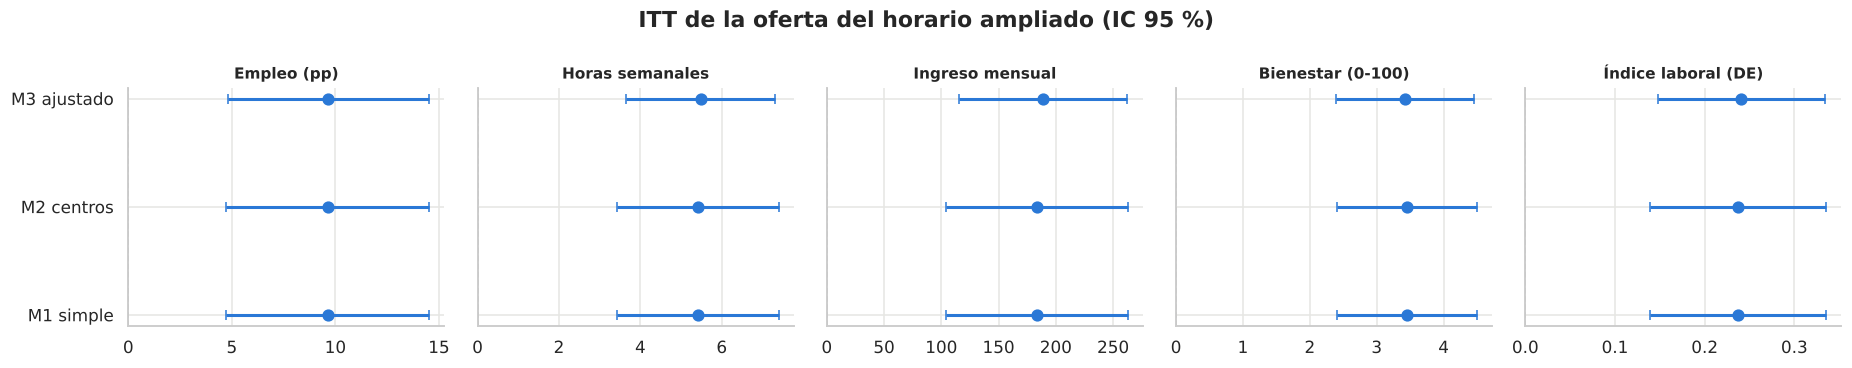

In [6]:
# Gráfico de bosque: ITT e IC95 por especificación
especs = ["simple", "centros", "ajustado"]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, y in zip(axes, resultados_itt):
    sub = tabla_itt[tabla_itt["resultado"] == y].set_index("modelo").loc[especs]
    pos = np.arange(len(especs))
    ax.errorbar(sub["itt"], pos, xerr=[sub["itt"] - sub["ic_inf"], sub["ic_sup"] - sub["itt"]],
                fmt="o", color=COLORS[1], ecolor=COLORS[1], capsize=3, ms=7, lw=2)
    ax.axvline(0, color=NEUTRAL, ls="--", lw=1)
    ax.set_title(NOMBRES[y], fontsize=10)
    ax.set_yticks(pos, ["M1 simple", "M2 centros", "M3 ajustado"])
    ax.set_xlim(left=min(0, sub["ic_inf"].min()) * 1.1 - 1e-9)
plt.suptitle("ITT de la oferta del horario ampliado (IC 95 %)", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación**

| Resultado | ITT (M3) | IC 95 % | Respecto de la media sin oferta |
|---|---|---|---|
| Empleo | **+9.7 pp** | [4.8, 14.5] | +17 % (de 57.0 % a 66.7 %) |
| Horas semanales | **+5.5 h** | [3.7, 7.3] | +27 % |
| Ingreso mensual | **+189 u.m.** | [116, 262] | +24 % |
| Bienestar | **+3.4 puntos** | [2.4, 4.5] | +6 % (≈ 0.33 DE) |
| Índice laboral | **+0.24 DE** | [0.15, 0.33] | — |

- **Ofrecer el horario ampliado aumenta el empleo, las horas, el ingreso y el bienestar** de las postulantes. En los cuatro resultados el intervalo excluye el cero con holgura, y los efectos superan los MDE calculados en 02.8.
- **Estabilidad:** M1, M2 y M3 dan prácticamente el mismo punto. Es lo esperable con un sorteo balanceado: el ajuste solo reduce el error estándar (−7 % en horas, −8 % en ingreso), como se anticipó en 03.7.
- **Coherencia con la teoría de cambio:** el aumento de ingreso (+189) es del orden de lo que implican las horas adicionales (+5.5 h × 4.33 semanas × ≈ 9.4 por hora ≈ 224). El efecto sobre el ingreso parece venir del mayor tiempo trabajado y no de mejores salarios por hora. El bienestar **sube**, lo que en promedio descarta un costo neto por la doble jornada (H4).
- **Magnitud para la política:** de cada 100 madres a las que se ofrece el servicio, unas 10 adicionales están trabajando en el seguimiento.

## 4.3 Corrección por multiplicidad

**Fundamento metodológico.** Según el plan de 00, el empleo es la prueba principal y no se ajusta. Las 3 pruebas secundarias (horas, ingreso, bienestar) sí: con 3 pruebas al 5 %, la probabilidad de al menos un falso positivo (FWER) llega hasta ≈ 14 % si todos los efectos fueran nulos y las pruebas fueran independientes (con resultados correlacionados es algo menor). El procedimiento de **Holm** [5] controla la FWER sin suponer independencia entre las pruebas y es más potente que Bonferroni.

> **En sencillo — multiplicidad:** si se lanzan muchas pruebas, alguna saldrá "significativa" por pura suerte, igual que al comprar muchos boletos de lotería es más probable que alguno gane. La **FWER** es la probabilidad de al menos un falso hallazgo en el conjunto. **Holm** ordena los valores $p$ de menor a mayor y exige al más pequeño superar un umbral más estricto ($0.05/3$), al siguiente $0.05/2$ y al último $0.05$. **Bonferroni** exige $0.05/3$ a todos por igual, lo que es más conservador.

In [7]:
# Familia secundaria (plan de 00): horas, ingreso y bienestar. El empleo (primario) se reporta sin ajuste.
SECUNDARIOS = ["horas_post", "ingreso_post_c", "bienestar_post"]
holm = tabla_itt[(tabla_itt["modelo"] == "ajustado") & tabla_itt["resultado"].isin(SECUNDARIOS)][["resultado", "itt", "p_valor"]].copy()
rechazo, p_holm, _, _ = multipletests(holm["p_valor"], alpha=ALPHA, method="holm")
holm["p_holm"], holm["rechaza_H0_holm"] = p_holm, rechazo
display(holm.set_index("resultado").style.format({"itt": "{:.3f}", "p_valor": "{:.2e}", "p_holm": "{:.2e}"}))

,itt,p_valor,p_holm,rechaza_H0_holm
resultado,,,,
horas_post,5.486,4.51e-09,9.03e-09,True
ingreso_post_c,188.807,4.00e-07,4.00e-07,True
bienestar_post,3.421,9.35e-11,2.80e-10,True


**Interpretación.** El resultado primario (empleo) tiene $p$ ≈ 0.0001 sin necesidad de ajuste. Los tres secundarios siguen siendo significativos después de la corrección de Holm (todos los $p$ ajustados < 0.001): no son fruto de haber probado varias hipótesis. Aunque se incluyera el empleo en la familia (4 pruebas), todos los $p$ ajustados seguirían < 0.001. El índice laboral (una sola prueba) lleva a la misma conclusión: +0.24 DE.

## 4.4 Inferencia por aleatorización

**Fundamento metodológico.** Se contrasta la hipótesis nula aguda de Fisher [6, 7], $H_0: Y_i(1) = Y_i(0)\ \forall i$ (la oferta no afectó a nadie). Bajo $H_0$ los resultados quedan fijos y la única fuente de aleatoriedad es el sorteo. Se reproduce el mecanismo inferido en 02.2 (permutar $Z$ **dentro de cada centro**, con el número de sorteadas fijo) y se recalcula el coeficiente M3. El valor $p$ es la proporción de permutaciones con un efecto al menos tan extremo como el observado. La prueba es válida con cualquier tamaño de muestra y no supone normalidad. Como no se pueden enumerar todos los sorteos posibles, el valor $p$ se **aproxima** con $B$ permutaciones al azar.

Se calcula el coeficiente con el teorema de Frisch-Waugh-Lovell: se residualizan $Y$ y $Z$ respecto de [centros + $X$] y luego se regresa un residuo sobre el otro. Esto permite hacer miles de permutaciones en segundos.

> **En sencillo:** la pregunta es "si el sorteo no hubiera servido de nada, ¿qué tan seguido saldría por azar una diferencia como la observada?". Se repite el sorteo 5 000 veces en la computadora, siempre con 50 % de sorteadas por centro, y se cuenta cuántas veces sale una diferencia igual o mayor. El "teorema de Frisch-Waugh-Lovell" es solo un atajo de cálculo: da exactamente el mismo coeficiente que la regresión completa, pero mucho más rápido.

,itt_obs,p_aleatorizacion,max_|sim|
empleo_post,9.661,0.000,8.998
horas_post,5.486,0.000,3.507
ingreso_post_c,188.807,0.000,129.426
bienestar_post,3.421,0.000,1.982
indice_laboral,0.241,0.000,0.183


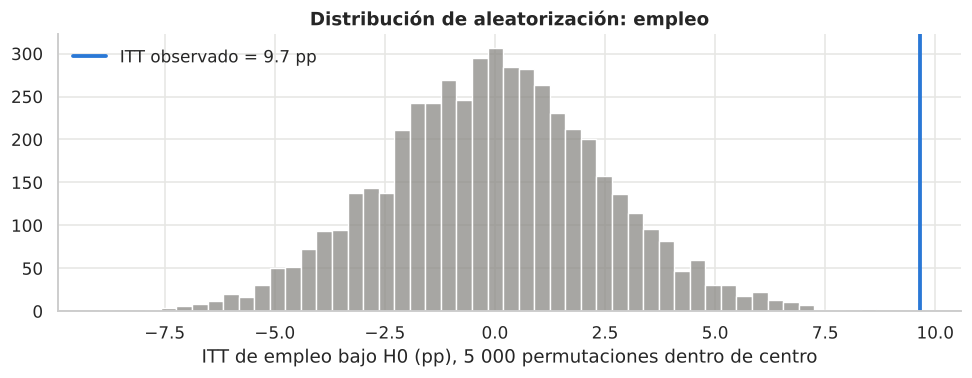

In [8]:
def ri_itt(data, resultado, B=5000, seed=SEED):
    # Coeficiente M3 observado y su distribución bajo permutaciones de Z dentro de centro (FWL)
    d = data.dropna(subset=[resultado]).reset_index(drop=True)
    X = pd.get_dummies(d[CENTER].astype("category"), drop_first=True, dtype=float)
    X = pd.concat([pd.Series(1.0, index=d.index, name="const"), X, d[BASELINE].astype(float)], axis=1).to_numpy()
    Q, _ = np.linalg.qr(X)
    resid = lambda v: v - Q @ (Q.T @ v)
    y_r = resid(d[resultado].to_numpy(float))
    z = d[Z].to_numpy(float)
    coef = lambda zz: (r := resid(zz)) @ y_r / (r @ r)
    rng = np.random.default_rng(seed)
    estratos = list(d.groupby(CENTER).indices.values())
    obs, sims = coef(z), np.empty(B)
    for b in range(B):
        zp = z.copy()
        for idx in estratos:
            zp[idx] = rng.permutation(z[idx])
        sims[b] = coef(zp)
    p = (1 + np.sum(np.abs(sims) >= abs(obs))) / (B + 1)
    return obs, sims, p

ri = {y: ri_itt(df, y) for y in resultados_itt}
tabla_ri = pd.DataFrame({y: {"itt_obs": ESCALA.get(y, 1) * o, "p_aleatorizacion": p,
                             "max_|sim|": ESCALA.get(y, 1) * np.abs(s).max()}
                         for y, (o, s, p) in ri.items()}).T
display(tabla_ri)

obs, sims, p = ri["empleo_post"]
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.histplot(100 * sims, bins=50, color=NEUTRAL, edgecolor="white", ax=ax)
ax.axvline(100 * obs, color=COLORS[1], lw=2.5, label=f"ITT observado = {100 * obs:.1f} pp")
ax.set_xlabel("ITT de empleo bajo H0 (pp), 5 000 permutaciones dentro de centro")
ax.set_ylabel(""); ax.legend(frameon=False)
ax.set_title("Distribución de aleatorización: empleo")
plt.tight_layout(); plt.show()

**Interpretación**

- **Ninguna** de las 5 000 reasignaciones del sorteo produjo un efecto tan grande como el observado, en ninguno de los resultados. El valor $p$ reportado es el mínimo que se puede obtener con $B = 5000$: $p = 1/5001 \approx 0.0002$. El $p$ verdadero es aún menor.
- Por ejemplo, para el empleo, el mayor ITT simulado bajo $H_0$ fue de 9.0 pp, menor que los 9.7 pp observados.
- Se rechaza que la oferta no tuvo efecto sobre nadie, sin depender de normalidad ni de errores asintóticos. Esta prueba se basa en el mecanismo de asignación inferido en 02.2 (permutación dentro de centro).

## 4.5 Primera etapa: ¿la oferta cambia el uso?

**Fundamento metodológico.** El LATE requiere un instrumento **relevante**, es decir, que $Z$ afecte $D$. Se estima $D_i = \gamma + \pi Z_i + \delta_c + X_i'\theta + v_i$. Con un instrumento y errores robustos, el F efectivo es $t^2$ [8]. Valores muy por encima de 10, o del umbral más exigente de Lee et al. [9], $F > 104.7$ para inferencia con $t$ convencional, descartan problemas de instrumento débil.

> **En sencillo — instrumento débil:** si el sorteo apenas cambiara el uso del servicio, el LATE dividiría por un número muy pequeño y cualquier ruido se amplificaría enormemente. El **estadístico F** mide qué tan fuerte es el "empujón" del sorteo sobre el uso: cuanto más alto, más confiable es el LATE.

In [9]:
fs = smf.ols(f"{D} ~ {Z} + C({CENTER}) + " + " + ".join(BASELINE), data=df).fit(cov_type="HC3")
pi_hat = fs.params[Z]
print(f"Primera etapa π = {pi_hat:.3f} (EE {fs.bse[Z]:.3f}); IC95 [{fs.conf_int().loc[Z, 0]:.3f}, {fs.conf_int().loc[Z, 1]:.3f}]")
print(f"F efectivo (t²) = {fs.tvalues[Z] ** 2:,.0f}")

Primera etapa π = 0.624 (EE 0.020); IC95 [0.584, 0.663]
F efectivo (t²) = 963


**Interpretación.** La oferta aumenta la probabilidad de usar el horario ampliado en **62 pp** (IC95 58-66), con F ≈ 960, muy por encima de cualquier umbral de instrumento débil. El denominador del LATE está estimado con mucha precisión: la incertidumbre del LATE viene casi toda del numerador (el ITT).

## 4.6 Efecto del uso entre cumplidoras (LATE)

**Fundamento metodológico.** Bajo los supuestos de independencia (sorteo), exclusión, monotonicidad y relevancia [10, 11]:

$$LATE = \frac{E[Y\mid Z=1]-E[Y\mid Z=0]}{E[D\mid Z=1]-E[D\mid Z=0]} = \frac{ITT}{\pi}$$

Se estima por **mínimos cuadrados en dos etapas (2SLS)**, con los mismos efectos fijos y covariables que M3 y errores robustos a heterocedasticidad (HC0, porque la librería no ofrece HC3; la diferencia es de ≈ 1 %). 2SLS calcula correctamente el error estándar del cociente, lo que no ocurre si se divide manualmente el ITT entre $\pi$.

> **En sencillo — por qué dividir ITT entre $\pi$:** si ofrecer la vacante sube el empleo en 10 pp, pero solo el 62 % de las sorteadas la usa *por* la oferta, todo ese efecto viene de ese 62 %. El efecto en ellas debe ser $10/0.62 \approx 16$ pp. Las siempre usuarias y las nunca usuarias hacen lo mismo con o sin sorteo, así que no aportan diferencia.
>
> **2SLS** hace este cálculo en dos pasos: (1) predice el uso con el sorteo; (2) relaciona el resultado con ese uso predicho, que solo varía por el azar del sorteo y, por lo tanto, está libre de autoselección.

Como contraste, se reportan dos estimadores **ingenuos**, que son sesgados por la autoselección documentada en 03.8:

- **Según uso (*as-treated*):** MCO de $Y$ sobre $D$ con los mismos controles.
- **Por protocolo:** compara a las sorteadas que usaron con las no sorteadas que no usaron. Descarta a quienes no cumplieron, con lo que se rompe la aleatorización.

> **En sencillo:** el sorteo garantiza que *sorteadas* y *no sorteadas* sean comparables, pero no que *usuarias* y *no usuarias* lo sean. Cualquier comparación por uso pierde esa garantía.

In [10]:
ctrl_formula = f"C({CENTER}) + " + " + ".join(BASELINE)
filas = []
for y in resultados_itt:
    d = df.dropna(subset=[y])
    esc = ESCALA.get(y, 1)
    # Errores robustos HC0 (linearmodels no implementa HC3; la diferencia con HC3 es de ≈ 1 %)
    iv = IV2SLS.from_formula(f"{y} ~ 1 + {ctrl_formula} + [{D} ~ {Z}]", data=d).fit(cov_type="robust")
    pi_y = smf.ols(f"{D} ~ {Z} + {ctrl_formula}", data=d).fit().params[Z]   # π en la misma muestra
    ic = iv.conf_int().loc[D]
    at = smf.ols(f"{y} ~ {D} + {ctrl_formula}", data=d).fit(cov_type="HC3")
    pp = d[((d[Z] == 1) & (d[D] == 1)) | ((d[Z] == 0) & (d[D] == 0))]
    pprot = smf.ols(f"{y} ~ {D} + {ctrl_formula}", data=pp).fit(cov_type="HC3")
    itt = tabla_itt.query("resultado == @y and modelo == 'ajustado'")["itt"].iloc[0]
    filas.append({"resultado": y, "ITT": itt, "LATE_2SLS": esc * iv.params[D], "ee_LATE": esc * iv.std_errors[D],
                  "ic_inf": esc * ic.iloc[0], "ic_sup": esc * ic.iloc[1], "p_LATE": iv.pvalues[D],
                  "Wald_ITT/π": itt / pi_y,
                  "ingenuo_uso": esc * at.params[D], "ingenuo_protocolo": esc * pprot.params[D]})
tabla_late = pd.DataFrame(filas).set_index("resultado")
display(tabla_late)

,ITT,LATE_2SLS,ee_LATE,ic_inf,ic_sup,p_LATE,Wald_ITT/π,ingenuo_uso,ingenuo_protocolo
resultado,,,,,,,,,
empleo_post,9.661,15.488,3.892,7.859,23.117,0.000,15.488,17.263,16.735
horas_post,5.486,8.796,1.448,5.959,11.633,0.000,8.796,9.676,9.406
ingreso_post_c,188.807,302.134,57.712,189.020,415.248,0.000,302.134,347.955,333.031
bienestar_post,3.421,5.485,0.823,3.872,7.097,0.000,5.485,5.192,5.277
indice_laboral,0.241,0.386,0.074,0.241,0.532,0.000,0.386,0.433,0.419


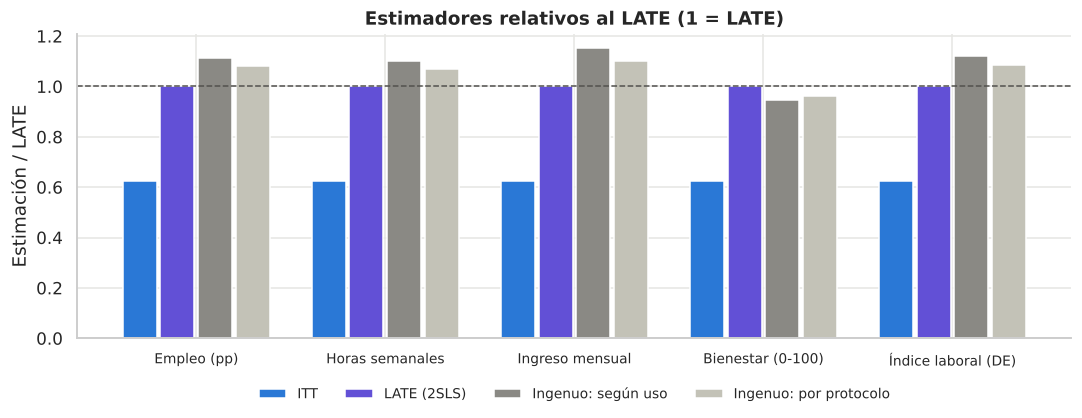

In [11]:
# Comparación visual: ITT, LATE e ingenuos (normalizados por el LATE para compartir eje)
comp = tabla_late[["ITT", "LATE_2SLS", "ingenuo_uso", "ingenuo_protocolo"]].div(tabla_late["LATE_2SLS"], axis=0)
etiquetas = {"ITT": "ITT", "LATE_2SLS": "LATE (2SLS)", "ingenuo_uso": "Ingenuo: según uso",
             "ingenuo_protocolo": "Ingenuo: por protocolo"}
colores = {"ITT": COLORS[1], "LATE_2SLS": "#6250d6", "ingenuo_uso": NEUTRAL, "ingenuo_protocolo": "#c3c2b7"}
fig, ax = plt.subplots(figsize=(10, 4))
ancho, x = 0.2, np.arange(len(comp))
for k, col in enumerate(comp.columns):
    ax.bar(x + (k - 1.5) * ancho, comp[col], width=ancho - 0.02, color=colores[col], label=etiquetas[col])
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xticks(x, [NOMBRES[y] for y in comp.index], fontsize=9)
ax.set_ylabel("Estimación / LATE")
ax.set_title("Estimadores relativos al LATE (1 = LATE)")
ax.legend(frameon=False, ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

**Interpretación**

- **LATE: entre las cumplidoras, usar el horario ampliado aumenta el empleo en 15.5 pp** (IC95 7.9-23.1), las horas en **8.8 por semana**, el ingreso en **302 u.m. al mes** y el bienestar en **5.5 puntos**. El cociente de Wald (ITT/π calculado en la misma muestra) coincide con 2SLS, como corresponde.
- **ITT o LATE:** el ITT es el 62 % del LATE (= $\pi$). El ITT responde "¿qué pasa si se ofrece el servicio a postulantes?", que es lo relevante para el presupuesto y la política. El LATE responde "¿qué le hace el servicio a quien lo usa por la oferta?", que es lo relevante para entender el mecanismo.
- **Estimadores ingenuos:** en empleo, horas, ingreso e índice, la comparación según uso y la comparación por protocolo superan al LATE entre 7 % y 15 %. En bienestar quedan algo por debajo. **Esta brecha no mide el sesgo de selección:** los estimadores ingenuos apuntan a otras poblaciones (incluyen siempre usuarias y nunca usuarias), así que mezclan autoselección con diferencias de población, y además la brecha es pequeña frente al IC del LATE. Lo que sí se sabe es que la comparación por uso no está protegida por el sorteo: su sesgo no se puede anticipar ni eliminar con un supuesto verificable. Por eso el LATE por IV es la estimación válida del efecto del uso.

## 4.7 ¿Quiénes son las cumplidoras?

**Objetivo.** El LATE solo vale para las cumplidoras, así que conviene saber si se parecen a la población y para quién es representativo.

**Fundamento metodológico.** Aunque no se puede identificar individualmente a una cumplidora, sí se pueden estimar las medias de sus características [12, 13]:
- Siempre usuarias: $E[X \mid D=1, Z=0]$. Nunca usuarias: $E[X \mid D=0, Z=1]$.
- Cumplidoras: $E[X\mid C] = \dfrac{E[XD\mid Z=1]-E[XD\mid Z=0]}{\pi}$.

Del mismo modo, la **media de $Y(0)$ de las cumplidoras**, $E[Y(1-D)\mid Z=0]-E[Y(1-D)\mid Z=1]$ dividido por $\pi$, da una referencia para expresar el LATE en términos relativos.

> **En sencillo:** el promedio de una característica en las cumplidoras se obtiene "por diferencia". Entre las sorteadas, las usuarias son cumplidoras + siempre usuarias. Entre las no sorteadas, las usuarias son solo siempre usuarias. Restando una de otra queda el aporte de las cumplidoras. $E[Y(0)]$ de las cumplidoras es cuánto habrían trabajado o ganado ellas *sin* el servicio: sirve para decir si +15 pp es mucho o poco.

In [12]:
z1, z0 = df[df[Z] == 1], df[df[Z] == 0]
pi_simple = z1[D].mean() - z0[D].mean()

def media_cumplidoras(v):
    return ((z1[v] * z1[D]).mean() - (z0[v] * z0[D]).mean()) / pi_simple

perfil = pd.DataFrame({
    "población": df[BASELINE].mean(),
    "siempre usuarias": z0.loc[z0[D] == 1, BASELINE].mean(),
    "nunca usuarias": z1.loc[z1[D] == 0, BASELINE].mean(),
    "cumplidoras": pd.Series({v: media_cumplidoras(v) for v in BASELINE}),
})
display(perfil)

y0_c = {}
for y in OUTCOMES:
    a, b = z0.dropna(subset=[y]), z1.dropna(subset=[y])
    y0_c[y] = ESCALA.get(y, 1) * ((a[y] * (1 - a[D])).mean() - (b[y] * (1 - b[D])).mean()) / pi_simple
rel = pd.DataFrame({"E[Y(0)] cumplidoras": y0_c, "LATE": tabla_late.loc[OUTCOMES, "LATE_2SLS"]})
rel["LATE_relativo_%"] = 100 * rel["LATE"] / rel["E[Y(0)] cumplidoras"]
display(rel)

,población,siempre usuarias,nunca usuarias,cumplidoras
edad_madre,29.408,29.783,29.477,29.285
numero_hijos,1.641,1.724,1.569,1.657
edad_menor,2.548,2.388,2.500,2.582
educ_madre,11.599,11.855,11.823,11.414
madre_sola,0.304,0.395,0.262,0.278
traslado_min,41.815,43.621,40.415,41.967
red_cuidado,0.438,0.322,0.600,0.435
empleo_pre,0.469,0.408,0.438,0.503
horas_pre,15.710,14.298,14.892,16.306
ingreso_pre,645.499,566.587,607.380,685.576


,E[Y(0)] cumplidoras,LATE,LATE_relativo_%
empleo_post,54.160,15.488,28.597
horas_post,18.605,8.796,47.277
ingreso_post_c,726.050,302.134,41.613
bienestar_post,55.536,5.485,9.876


**Interpretación**

- **Las cumplidoras se parecen mucho a la población postulante:** las diferencias en todas las características son pequeñas (empleo previo 50 % frente a 47 %; madre sola 28 % frente a 30 %). El LATE es razonablemente representativo de la población postulante en lo observable.
- **Siempre usuarias** (usan aun sin ser sorteadas): más madres solas (40 %), menos red de cuidado (32 %) y menos empleo previo (41 %). Son el grupo de mayor necesidad, que consigue acceso por otras vías.
- **Nunca usuarias** (no usan aunque sean sorteadas): **más red de cuidado (60 %)**. Tienen una alternativa de cuidado y no necesitan el servicio. Esto es coherente con la teoría de cambio.
- **En términos relativos**, el LATE equivale a +29 % de empleo, +47 % de horas y +42 % de ingreso respecto de lo que esas mismas cumplidoras habrían tenido sin el servicio, y a ≈ 0.5 DE de bienestar.

## 4.8 Heterogeneidad preespecificada

**Objetivo.** Probar H5: ¿el efecto es mayor donde la restricción de cuidado es más fuerte?

**Fundamento metodológico.** Para cada moderador $M$ definido en 00 (madre sola, sin red, restricción alta, empleo previo) se estima

$$Y_i = \alpha + \tau Z_i + \lambda M_i + \phi\,(Z_i \times M_i) + \delta_c + X_i'\beta + \varepsilon_i$$

$\phi$ es la diferencia de ITT entre subgrupos.

> **En sencillo — moderador e interacción:** un **moderador** es una característica que podría hacer que el efecto sea más grande o más chico (por ejemplo, ser madre sola). El término $Z \times M$ (**interacción**) mide justamente esa diferencia: cuánto más (o menos) efecto tiene el sorteo en el subgrupo $M=1$ que en el resto.

Tres cuidados:

1. **Los subgrupos se fijaron antes** (00), no después de ver los datos.
2. Con 4 moderadores × 4 resultados hay 16 pruebas: se aplica Holm por resultado.
3. Una diferencia en el ITT puede deberse a una diferencia en el **cumplimiento** y no en el efecto del uso. Por eso también se reporta la primera etapa por subgrupo.

In [13]:
MODERADORES = {"madre_sola": "Madre sola", "sin_red": "Sin red de cuidado",
               "restriccion_alta": "Sola y sin red", "empleo_pre": "Trabajaba antes"}

def itt_subgrupos(data, resultado, moderador):
    # ITT en M=0 y M=1, diferencia (interacción), y primera etapa por subgrupo
    covs = [v for v in BASELINE if v != moderador and not (moderador == "sin_red" and v == "red_cuidado")
            and not (moderador == "restriccion_alta" and v in ("madre_sola", "red_cuidado"))]
    d = data.dropna(subset=[resultado])
    f = f"{resultado} ~ {Z} * {moderador} + C({CENTER}) + " + " + ".join(covs)
    m = smf.ols(f, data=d).fit(cov_type="HC3")
    esc = ESCALA.get(resultado, 1)
    itt0 = m.params[Z]
    itt1 = m.params[Z] + m.params[f"{Z}:{moderador}"]
    v1 = m.cov_params().loc[[Z, f"{Z}:{moderador}"], [Z, f"{Z}:{moderador}"]].to_numpy().sum()
    fs_g = d.groupby(moderador).apply(lambda g: g.loc[g[Z] == 1, D].mean() - g.loc[g[Z] == 0, D].mean())
    return {"resultado": resultado, "moderador": MODERADORES[moderador],
            "itt_M0": esc * itt0, "ee_M0": esc * m.bse[Z], "itt_M1": esc * itt1, "ee_M1": esc * np.sqrt(v1),
            "diferencia": esc * m.params[f"{Z}:{moderador}"], "ee_dif": esc * m.bse[f"{Z}:{moderador}"],
            "p_dif": m.pvalues[f"{Z}:{moderador}"], "π_M0": fs_g.loc[0], "π_M1": fs_g.loc[1],
            "n_M1": int(d[moderador].sum())}

het = pd.DataFrame([itt_subgrupos(df, y, m) for y in OUTCOMES for m in MODERADORES])
het["p_dif_holm"] = het.groupby("resultado")["p_dif"].transform(lambda p: multipletests(p, method="holm")[1])
display(het.set_index(["resultado", "moderador"]))

itt_M0  ee_M0  itt_M1  ee_M1  diferencia  ee_dif  p_dif  π_M0  π_M1  n_M1  p_dif_holm
resultado      moderador                                                                                                
empleo_post    Madre sola          11.052  2.957   6.469  4.577      -4.583   5.454  0.401 0.640 0.590   456       1.000
               Sin red de cuidado   6.792  3.724  11.889  3.330       5.097   4.997  0.308 0.614 0.633   843       1.000
               Sola y sin red       9.292  2.705  11.423  6.270       2.130   6.837  0.755 0.632 0.590   250       1.000
               Trabajaba antes      7.530  3.518  12.073  3.490       4.543   4.958  0.359 0.591 0.662   704       1.000
horas_post     Madre sola           6.604  1.119   2.922  1.713      -3.683   2.050  0.072 0.640 0.590   456       0.289
               Sin red de cuidado   5.322  1.414   5.614  1.249       0.292   1.887  0.877 0.614 0.633   843       0.877
               Sola y sin red       5.854  1.024   3.593  2.316      -2.261   2.536  0.373 0.632 0.590   250       0.745
               Trabajaba antes      3.956  1.130   7.219  1.533       3.264   1.907  0.087 0.591 0.662   704       0.289
ingreso_post_c Madre sola         223.808 44.367 108.728 68.970    -115.080  82.171  0.161 0.642 0.588   445       0.645
               Sin red de cuidado 157.340 56.008 213.470 50.009      56.131  75.163  0.455 0.615 0.634   818       0.910
               Sola y sin red     190.648 40.575 179.633 95.080     -11.014 103.586  0.915 0.633 0.587   245       0.915
               Trabajaba antes    149.979 49.869 232.916 56.134      82.937  75.242  0.270 0.593 0.661   684       0.811
bienestar_post Madre sola           3.606  0.636   2.997  0.949      -0.608   1.141  0.594 0.640 0.590   456       1.000
               Sin red de cuidado   3.018  0.822   3.734  0.690       0.716   1.076  0.505 0.614 0.633   843       1.000
               Sola y sin red       3.302  0.581   4.074  1.328       0.772   1.453  0.595 0.632 0.590   250       1.000
               Trabajaba antes      3.556  0.736   3.268  0.759      -0.287   1.058  0.786 0.591 0.662   704       1.000

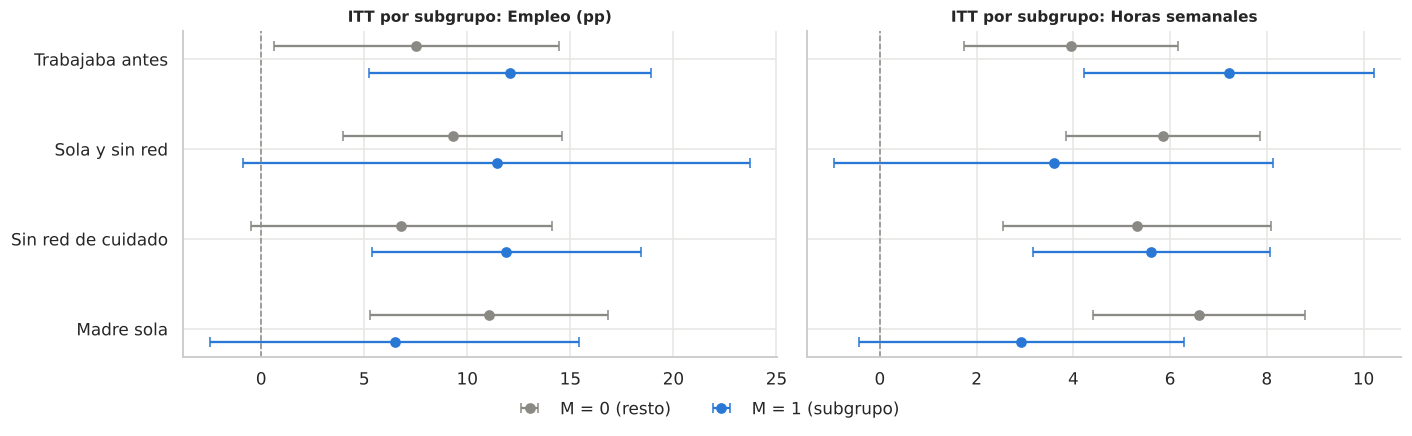

In [14]:
# ITT de empleo y horas por subgrupo con IC95
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, y in zip(axes, ["empleo_post", "horas_post"]):
    sub = het[het["resultado"] == y].reset_index(drop=True)
    pos = np.arange(len(sub))
    ax.errorbar(sub["itt_M0"], pos + 0.15, xerr=1.96 * sub["ee_M0"], fmt="o", color=NEUTRAL, capsize=3, label="M = 0 (resto)")
    ax.errorbar(sub["itt_M1"], pos - 0.15, xerr=1.96 * sub["ee_M1"], fmt="o", color=COLORS[1], capsize=3, label="M = 1 (subgrupo)")
    ax.axvline(0, color=NEUTRAL, ls="--", lw=1)
    ax.set_yticks(pos, sub["moderador"]); ax.set_title(f"ITT por subgrupo: {NOMBRES[y]}", fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()

**Interpretación**

- **Ninguna interacción es significativa después de Holm** (el menor $p$ ajustado es 0.29). **No se encontró evidencia estadística a favor de H5**: no se puede afirmar que el efecto difiera según la restricción de cuidado o el empleo previo. Esto no equivale a demostrar que el efecto es igual para todas.
- Las direcciones puntuales son mixtas y en parte contrarias a H5: el efecto en las madres solas es **menor**, no mayor (empleo 6.5 frente a 11.1 pp; horas 2.9 frente a 6.6), y en quienes ya trabajaban es **mayor** (12.1 frente a 7.5 pp), lo que coincide con el patrón descriptivo de retención de 03.6. En empleo, "sin red de cuidado" (11.9 frente a 6.8 pp) y "sola y sin red" (11.4 frente a 9.3 pp) sí van en la dirección esperada. Ninguna de estas diferencias es significativa.
- La primera etapa es parecida entre subgrupos ($\pi$ de 0.59 a 0.66). Las diferencias puntuales en el ITT no se explican principalmente por diferencias de cumplimiento. En "trabajaba antes", $\pi$ es algo mayor (0.66 frente a 0.59) y eso explica una parte pequeña de su mayor ITT.
- **Cautela:** el experimento no tiene poder para detectar heterogeneidad. El error estándar de las interacciones en empleo es de unos 5-7 pp, así que solo se detectarían diferencias de **14-19 pp** entre subgrupos. "No significativo" no significa "efecto homogéneo". Estos resultados deben tomarse como exploratorios y no son base suficiente para focalizar el programa.

## 4.9 Nota sobre el margen intensivo

Es tentador estimar el efecto sobre las horas **solo entre las empleadas**. (Las *always-employed* son las madres que trabajarían con o sin oferta.) Pero la oferta cambia *quién* está empleada (ITT de +10 pp): las empleadas del grupo con oferta incluyen madres que sin oferta no trabajarían, y que probablemente trabajan menos horas o ganan menos. Condicionar en `empleo_post = 1` es condicionar en un **colisionador** (00), y la comparación resultante no tiene interpretación causal.

Por eso, en este notebook, horas e ingreso se miden en toda la población (efecto total = extensivo + intensivo). El efecto intensivo sobre las madres que trabajarían **con o sin oferta** se acota con **cotas de Lee** en 05.

## 4.10 Síntesis de resultados

> **Revisión posterior: ver el notebook 06.** Este notebook estima la incertidumbre con errores HC3 a nivel de cada madre. Tras la exposición del análisis, y a partir de una observación del instructor, se reestimó la inferencia **agrupando por centro**, porque los cinco centros pueden entenderse como una muestra de la red municipal. Los efectos estimados no cambian y siguen siendo significativos, pero con más incertidumbre: por ejemplo, el IC 95 % del empleo pasa de 4.8-14.5 a 3.4-16.0 pp. Para conclusiones sobre otros centros, la inferencia de referencia es la del [notebook 06](06_inferencia_conglomerados.ipynb).

| Resultado | ITT (IC 95 %) | LATE (IC 95 %) | ¿Significativo tras Holm? | ¿Significativo por aleatorización? |
|---|---|---|---|---|
| Empleo | +9.7 pp (4.8, 14.5) | +15.5 pp (7.9, 23.1) | Primario (no se ajusta); p ≈ 0.0001 | Sí (p < 0.001) |
| Horas semanales | +5.5 (3.7, 7.3) | +8.8 (6.0, 11.6) | Sí | Sí (p < 0.001) |
| Ingreso mensual (u.m.) | +189 (116, 262) | +302 (189, 415) | Sí | Sí (p < 0.001) |
| Bienestar | +3.4 (2.4, 4.5) | +5.5 (3.9, 7.1) | Sí | Sí (p < 0.001) |

*Holm:* el efecto sigue siendo significativo después de corregir por haber probado varios resultados. *Aleatorización:* ninguno de los 5 000 sorteos simulados produjo un efecto tan grande.

**Conclusión principal.** Ofrecer horario ampliado de cuidado infantil a madres postulantes aumenta su empleo, sus horas, su ingreso laboral y su bienestar. Los efectos son estables entre especificaciones y robustos a multiplicidad y a la inferencia por aleatorización.

**Supuestos de los que depende cada resultado**

- **ITT:** solo del sorteo (inferido y examinado en 02) y de que los faltantes de ingreso no sesguen el resultado (2.6 %, se prueba en 05).
- **LATE:** además, de la **restricción de exclusión** (que la oferta no afecte el resultado por otra vía, por ejemplo la expectativa o el ánimo de quien sale sorteada, lo que sería especialmente relevante para el bienestar) y de la **monotonicidad**. Ambos se examinan en 05.
- **Heterogeneidad:** sin evidencia de diferencias; el poder para detectarlas es bajo.

**Pendiente para 05:** robustez de especificación, faltantes de ingreso (IPW, Lee, ajuste delta), margen intensivo (Lee) y sensibilidad del LATE a violaciones de la exclusión.

## Referencias

1. MacKinnon, J. G. y White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics*, 29(3), 305-325. https://doi.org/10.1016/0304-4076(85)90158-7
2. Cameron, A. C. y Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources*, 50(2), 317-372. https://doi.org/10.3368/jhr.50.2.317
3. Freedman, D. A. (2008). On regression adjustments to experimental data. *Advances in Applied Mathematics*, 40(2), 180-193. https://doi.org/10.1016/j.aam.2006.12.003
4. Lin, W. (2013). Agnostic notes on regression adjustments to experimental data: Reexamining Freedman's critique. *Annals of Applied Statistics*, 7(1), 295-318. https://doi.org/10.1214/12-AOAS583
5. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65-70.
6. Fisher, R. A. (1935). *The Design of Experiments*. Oliver & Boyd.
7. Athey, S. e Imbens, G. W. (2017). The econometrics of randomized experiments. En A. V. Banerjee y E. Duflo (eds.), *Handbook of Economic Field Experiments* (vol. 1, pp. 73-140). North-Holland. https://doi.org/10.1016/bs.hefe.2016.10.003
8. Montiel Olea, J. L. y Pflueger, C. (2013). A robust test for weak instruments. *Journal of Business & Economic Statistics*, 31(3), 358-369.
9. Lee, D. S., McCrary, J., Moreira, M. J. y Porter, J. (2022). Valid t-ratio inference for IV. *American Economic Review*, 112(10), 3260-3290. https://doi.org/10.1257/aer.20211063
10. Imbens, G. W. y Angrist, J. D. (1994). Identification and estimation of local average treatment effects. *Econometrica*, 62(2), 467-475. https://doi.org/10.2307/2951620
11. Angrist, J. D., Imbens, G. W. y Rubin, D. B. (1996). Identification of causal effects using instrumental variables. *Journal of the American Statistical Association*, 91(434), 444-455. https://doi.org/10.1080/01621459.1996.10476902
12. Abadie, A. (2003). Semiparametric instrumental variable estimation of treatment response models. *Journal of Econometrics*, 113(2), 231-263. https://doi.org/10.1016/S0304-4076(02)00201-4
13. Angrist, J. D. y Pischke, J.-S. (2009). *Mostly Harmless Econometrics: An Empiricist's Companion*. Princeton University Press.